# Lab 01 — bAbI Dataset Exploration
**Goal:** inspect the original English 10k bAbI data, convert stories to question-answer examples, compare QA1–QA3, and document a leakage-safe validation protocol.


**Data source:** [original bAbI tasks archive](https://s3.amazonaws.com/text-datasets/babi_tasks_1-20_v1-2.tar.gz). The dataset contains story lines and question lines; question lines provide answers and supporting-fact IDs.

In [ ]:
import json
from memn2n.data import flatten_story
from pathlib import Path
from urllib.request import urlretrieve
import tarfile

##  Download the  bAbI archive 

In [13]:
archive_path = Path("../data/raw/babi_tasks_1-20_v1-2.tar.gz")
archive_path.parent.mkdir(parents=True, exist_ok=True)

if not archive_path.exists():
    urlretrieve("https://s3.amazonaws.com/text-datasets/babi_tasks_1-20_v1-2.tar.gz", archive_path)

archive = tarfile.open(archive_path, mode="r:gz")
print("Archive ready:", archive_path)

Archive ready: ..\data\raw\babi_tasks_1-20_v1-2.tar.gz


## Load raw QA1, QA2, QA3 text files

In [3]:
TASK_NAMES = {
    "QA1": "qa1_single-supporting-fact",
    "QA2": "qa2_two-supporting-facts",
    "QA3": "qa3_three-supporting-facts",
}

def load_babi_lines(task, split):
    filename = f"tasks_1-20_v1-2/en-10k/{TASK_NAMES[task]}_{split}.txt"
    with archive.extractfile(filename) as f:
        return f.read().decode("utf-8").splitlines()

raw = {(task, split): load_babi_lines(task, split)
       for task in TASK_NAMES for split in ("train", "test")}
for task in TASK_NAMES:
    print(task, "train lines:", len(raw[(task, "train")]),
          "| test lines:", len(raw[(task, "test")]))

QA1 train lines: 30000 | test lines: 3000
QA2 train lines: 53992 | test lines: 5398
QA3 train lines: 158786 | test lines: 15710


In [16]:
for task, name in [
    ("qa1", "single-supporting-fact"),
    ("qa2", "two-supporting-facts"),
    ("qa3", "three-supporting-facts")
]:
    print(f"\n========== {task.upper()} ==========")

    path = f"tasks_1-20_v1-2/en-10k/{task}_{name}_train.txt"
    lines = archive.extractfile(path).read().decode("utf-8").splitlines()

    for line in lines[:10]:
        print(line)


========== QA1 ==========
1 Mary moved to the bathroom.
2 John went to the hallway.
3 Where is Mary? 	bathroom	1
4 Daniel went back to the hallway.
5 Sandra moved to the garden.
6 Where is Daniel? 	hallway	4
7 John moved to the office.
8 Sandra journeyed to the bathroom.
9 Where is Daniel? 	hallway	4
10 Mary moved to the hallway.

========== QA2 ==========
1 Mary moved to the bathroom.
2 Sandra journeyed to the bedroom.
3 Mary got the football there.
4 John went to the kitchen.
5 Mary went back to the kitchen.
6 Mary went back to the garden.
7 Where is the football? 	garden	3 6
8 Sandra went back to the office.
9 John moved to the office.
10 Sandra journeyed to the hallway.

========== QA3 ==========
1 Mary moved to the bathroom.
2 Sandra journeyed to the bedroom.
3 Mary got the football there.
4 John went back to the bedroom.
5 Mary journeyed to the office.
6 John journeyed to the office.
7 John took the milk.
8 Daniel went back to the kitchen.
9 John moved to the bedroom.
10 Daniel 

## Parse raw text into structured story records
A new story begins whenever the line ID resets to `1`. Questions carry answers and supporting-fact IDs. This reproduces the field layout used by our local `flatten_story()` function.

In [4]:
def parse_babi(lines):
    records = []
    current = []

    def add_story():
        if current:
            records.append({"story": {
                key: [item[key] for item in current]
                for key in ("id", "type", "text", "supporting_ids", "answer")
            }})

    for line in lines:
        number, content = line.split(" ", 1)
        if number == "1" and current:
            add_story()
            current = []

        pieces = content.split("\t")
        is_question = len(pieces) == 3
        current.append({
            "id": number,
            "type": int(is_question),
            "text": pieces[0],
            "supporting_ids": pieces[2].split() if is_question else [],
            "answer": pieces[1] if is_question else "",
        })

    add_story()
    return records

datasets = {(task, split): parse_babi(raw[(task, split)])
            for task in TASK_NAMES for split in ("train", "test")}
for task in TASK_NAMES:
    print(task, "train stories:", len(datasets[(task, "train")]),
          "| test stories:", len(datasets[(task, "test")]))

QA1 train stories: 2000 | test stories: 200
QA2 train stories: 2000 | test stories: 200
QA3 train stories: 2000 | test stories: 200


## Inspect a structured story and its questions

In [5]:
sample = datasets[("QA1", "train")][0]["story"]
for i, kind in enumerate(sample["type"]):
    if kind == 1:
        print("Question:", sample["text"][i])
        print("Answer:", sample["answer"][i])
        print("Supporting IDs:", sample["supporting_ids"][i])
        print("---")

Question: Where is Mary? 
Answer: bathroom
Supporting IDs: ['1']
---
Question: Where is Daniel? 
Answer: hallway
Supporting IDs: ['4']
---
Question: Where is Daniel? 
Answer: hallway
Supporting IDs: ['4']
---
Question: Where is Daniel? 
Answer: office
Supporting IDs: ['11']
---
Question: Where is Sandra? 
Answer: bathroom
Supporting IDs: ['8']
---


## Convert stories into individual QA examples
The question context contains only **earlier statements**, not future facts.

In [6]:
flat = {}
for task in TASK_NAMES:
    for split in ("train", "test"):
        rows = []
        for story_idx, record in enumerate(datasets[(task, split)]):
            rows.extend(flatten_story(record, source_id=f"{task}-{split}-{story_idx}"))
        flat[(task, split)] = rows

for task in TASK_NAMES:
    print(task, "train QA:", len(flat[(task, "train")]),
          "| test QA:", len(flat[(task, "test")]))

QA1 train QA: 10000 | test QA: 1000
QA2 train QA: 10000 | test QA: 1000
QA3 train QA: 10000 | test QA: 1000


## Compare QA1, QA2, and QA3 examples

In [7]:
for task in TASK_NAMES:
    first = flat[(task, "train")][0]
    print(f"\n{task}: {first['question']} → {first['answer']}")
    print("Supporting IDs:", first["supporting_ids"])
    print("Context sentences:", len(first["context"]))
    print("Context:", first["context"][:5])


QA1: Where is Mary?  → bathroom
Supporting IDs: ['1']
Context sentences: 2
Context: ['Mary moved to the bathroom.', 'John went to the hallway.']

QA2: Where is the football?  → garden
Supporting IDs: ['3', '6']
Context sentences: 6
Context: ['Mary moved to the bathroom.', 'Sandra journeyed to the bedroom.', 'Mary got the football there.', 'John went to the kitchen.', 'Mary went back to the kitchen.']

QA3: Where was the football before the bathroom?  → office
Supporting IDs: ['23', '17', '5']
Context sentences: 24
Context: ['Mary moved to the bathroom.', 'Sandra journeyed to the bedroom.', 'Mary got the football there.', 'John went back to the bedroom.', 'Mary journeyed to the office.']


## Dataset summary statistics

In [8]:
import pandas as pd

summary = []
for task in TASK_NAMES:
    for split in ("train", "test"):
        rows = flat[(task, split)]
        summary.append({
            "task": task,
            "split": split,
            "story_records": len(datasets[(task, split)]),
            "qa_examples": len(rows),
            "avg_context_sentences": round(sum(len(r["context"]) for r in rows) / len(rows), 2),
            "avg_supporting_facts": round(sum(len(r["supporting_ids"]) for r in rows) / len(rows), 2),
        })
summary_df = pd.DataFrame(summary)
display(summary_df)

,task,split,story_records,qa_examples,avg_context_sentences,avg_supporting_facts
0,QA1,train,2000,10000,6.00,1.0
1,QA1,test,200,1000,6.00,1.0
2,QA2,train,2000,10000,15.58,2.0
3,QA2,test,200,1000,15.43,2.0
4,QA3,train,2000,10000,51.95,3.0
5,QA3,test,200,1000,50.97,3.0


## Vocabulary, lengths, and answer frequency
This is an **exploratory** word tokenizer; final preprocessing decisions belong in Lab 02.

In [9]:
from collections import Counter
import re

def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

stats = []
for task in TASK_NAMES:
    rows = flat[(task, "train")]
    vocabulary = set()
    lengths = []
    answers = Counter()
    for r in rows:
        answers[r["answer"]] += 1
        vocabulary.update(tokenize(r["question"]))
        for sentence in r["context"]:
            words = tokenize(sentence)
            vocabulary.update(words)
            lengths.append(len(words))
    stats.append({
        "task": task,
        "vocabulary_size": len(vocabulary),
        "avg_sentence_tokens": round(sum(lengths) / len(lengths), 2),
        "max_sentence_tokens": max(lengths),
        "distinct_answers": len(answers),
        "most_common_answer": answers.most_common(1)[0][0],
    })
display(pd.DataFrame(stats))

,task,vocabulary_size,avg_sentence_tokens,max_sentence_tokens,distinct_answers,most_common_answer
0,QA1,19,5.20,6,6,bathroom
1,QA2,33,5.11,6,6,garden
2,QA3,34,4.93,6,6,bathroom


## Plan train / validation / test split
Use the official test set only for final evaluation. Create validation from **training stories** (not independently from questions), with a fixed seed.

In [10]:
from sklearn.model_selection import train_test_split

SEED = 42
splits = {}
split_rows = []
for task in TASK_NAMES:
    story_ids = list(range(len(datasets[(task, "train")])))
    train_ids, val_ids = train_test_split(story_ids, test_size=0.10, random_state=SEED)
    assert set(train_ids).isdisjoint(val_ids)
    splits[task] = {"train_story_ids": train_ids, "val_story_ids": val_ids}
    split_rows.append({
        "task": task,
        "train_stories": len(train_ids),
        "validation_stories": len(val_ids),
        "test_stories": len(datasets[(task, "test")]),
    })
display(pd.DataFrame(split_rows))

,task,train_stories,validation_stories,test_stories
0,QA1,1800,200,200
1,QA2,1800,200,200
2,QA3,1800,200,200


## Visualize the dataset 

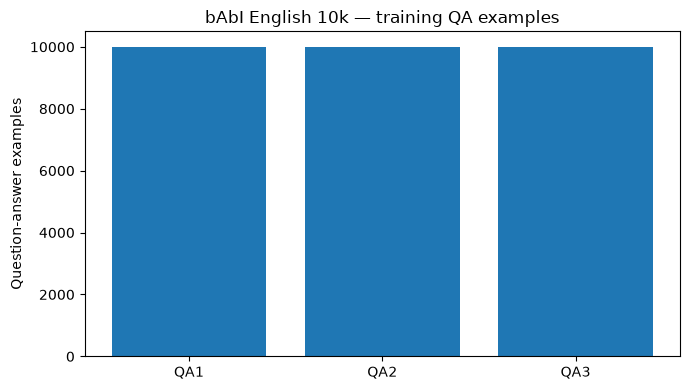

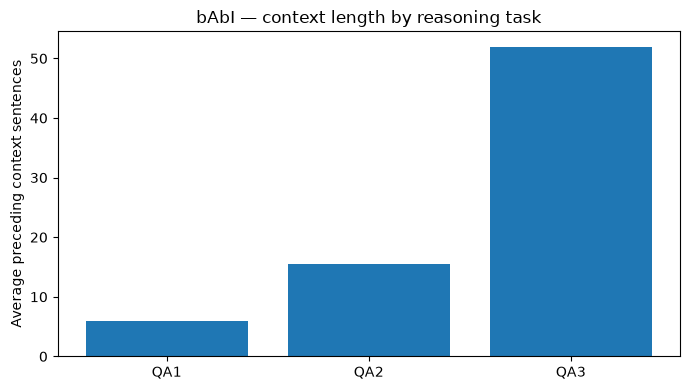

In [11]:
import matplotlib.pyplot as plt

train_summary = summary_df[summary_df["split"] == "train"]

plt.figure(figsize=(7, 4))
plt.bar(train_summary["task"], train_summary["qa_examples"])
plt.ylabel("Question-answer examples")
plt.title("bAbI English 10k — training QA examples")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
plt.bar(train_summary["task"], train_summary["avg_context_sentences"])
plt.ylabel("Average preceding context sentences")
plt.title("bAbI — context length by reasoning task")
plt.tight_layout()
plt.show()

##  Findings & preprocessing decisions
Complete this research log after executing the notebook:

- **Dataset:** Original bAbI 1–20 archive, `en-10k`, tasks QA1, QA2, QA3.
- **Supervision:** Use `answer` for model training. Keep `supporting_ids` for analysis, not direct attention supervision.
- **Splits:** Official test held out; validation split by training **story record**, seed 42.
- **Tokenizer:** Simple word-level tokenizer for exploration; finalize vocabulary, OOV handling, and padding in Lab 02.
- **Quality checks:** Questions must only see past context; supporting IDs must correspond to available context entries; no train/validation story overlap.
- **Research:** Distractors will be added later under a controlled, answer-preserving protocol.